# Mind Reading: сравнение подходов (EEG → какое видео смотрели)

Один ноутбук, в котором все подходы прогоняются через **общий интерфейс** и сравниваются в одной таблице (top-1 / top-5 / MRR на sub-01…04). Положите ноутбук рядом с папками `trn/`, `tst/`, `tst_stim/`, `stimuli_train/`, `stimuli_test/` (или задайте `MR_ROOT`).

**Что сравнивается**

| Ось | Варианты |
|---|---|
| Предобработка ЭЭГ | фильтр 0,5–40 Гц, z-score по каналу, вычитание среднего ERP, Euclidean Alignment (EA) |
| Признаки стимула | AlexNet (как в бейзлайне), DINOv2, CLIP, V-JEPA 2, VideoMAE; аудио: огибающая/onset, Whisper, CLAP; всё с временной осью или усреднённое |
| Метод | `ridge_encoding` (признаки → ЭЭГ, как бейзлайн), `ridge_decoding` (ЭЭГ → эмбеддинг), `rcca`, `contrastive` (InfoNCE) |
| Дообучение | замороженные признаки → soft-targets → адаптеры субъектов → дообучение последних блоков видео-бэкбона (`finetune_backbone`) |
| Постобработка | CSLS, слияние матриц сходства, (опционально) оптимальное назначение |

**Правила организаторов, которые заложены в код**
- Для обучения используются только train-записи всех шести субъектов.
- Тестовые записи sub-01…04 идут **только в оценку и выбор модели**; как шаблоны для sub-05/06 не используются.
- Тестовые записи используются лишь для безметочной нормализации (ковариация для EA). PCA и z-score признаков видео считаются по train-видео.
- Порядок строк предсказаний для sub-05/06 совпадает с порядком в `tst/sub-XX_tst.npy` (ничего не пересортировывается).

**Режимы запуска:** `MR_SYNTHETIC=1` включает синтетические данные для проверки пайплайна, `MR_FAST=1` резко сокращает эпохи.

In [9]:
import os, shutil, imageio_ffmpeg
src = imageio_ffmpeg.get_ffmpeg_exe()
d = os.path.abspath('bin'); os.makedirs(d, exist_ok=True)
shutil.copy(src, os.path.join(d, 'ffmpeg.exe'))
os.environ['PATH'] = d + os.pathsep + os.environ['PATH']
!ffmpeg -version

ffmpeg version 7.1-essentials_build-www.gyan.dev Copyright (c) 2000-2024 the FFmpeg developers
built with gcc 14.2.0 (Rev1, Built by MSYS2 project)
configuration: --enable-gpl --enable-version3 --enable-static --disable-w32threads --disable-autodetect --enable-fontconfig --enable-iconv --enable-gnutls --enable-libxml2 --enable-gmp --enable-bzlib --enable-lzma --enable-zlib --enable-libsrt --enable-libssh --enable-libzmq --enable-avisynth --enable-sdl2 --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxvid --enable-libaom --enable-libopenjpeg --enable-libvpx --enable-mediafoundation --enable-libass --enable-libfreetype --enable-libfribidi --enable-libharfbuzz --enable-libvidstab --enable-libvmaf --enable-libzimg --enable-amf --enable-cuda-llvm --enable-cuvid --enable-dxva2 --enable-d3d11va --enable-d3d12va --enable-ffnvcodec --enable-libvpl --enable-nvdec --enable-nvenc --enable-vaapi --enable-libgme --enable-libopenmpt --enable-libopencore-amrwb --enable-libmp3lame --enabl

## 0. Конфигурация

In [1]:
import os, glob, json, math, time, copy, subprocess, warnings, random
from dataclasses import dataclass
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, resample_poly
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import PCA
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

ROOT = Path(os.environ.get('MR_ROOT', '.'))
TRN_DIR, TST_DIR, TST_STIM_DIR = ROOT / 'trn', ROOT / 'tst', ROOT / 'tst_stim'
VID_TRN_DIR, VID_TST_DIR = ROOT / 'stimuli_train', ROOT / 'stimuli_test'
CACHE = ROOT / 'cache'; CACHE.mkdir(exist_ok=True, parents=True)
OUT_DIR = ROOT / 'submission'; OUT_DIR.mkdir(exist_ok=True, parents=True)

USE_SYNTHETIC = os.environ.get('MR_SYNTHETIC', '0') == '1'
FAST = os.environ.get('MR_FAST', '0') == '1'

ALL_SUBJECTS = [1, 2, 3, 4, 5, 6]
DEV_SUBJECTS = [1, 2, 3, 4]      # test labels available: validation / model selection only
HELD_SUBJECTS = [5, 6]           # test labels withheld
FS_RAW, DEC = 500, 5             # 500 Hz -> 100 Hz
FS = FS_RAW // DEC
N_T = 300                        # samples per trial after decimation (3 s at 100 Hz)
N_TRAIN_VIDEOS, N_TEST_VIDEOS, TEST_ID0 = 1000, 102, 1001
SEED = 0
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


seed_all()
print('device:', DEVICE, '| data:', 'SYNTHETIC' if USE_SYNTHETIC else 'real', '| fast' if FAST else '')

device: cpu | data: real 


## 1. Данные

In [2]:
@dataclass
class Data:
    trn_eeg: dict   # sub -> (n, C, T) float32, trials in file order
    trn_ids: dict   # sub -> (n,) video ids (1..1000)
    tst_eeg: dict   # sub -> (102, C, T), ORIGINAL (shuffled) order, never reorder
    tst_gt: dict    # sub -> (102,) true video ids (dev subjects only)


def load_real():
    trn_eeg, trn_ids, tst_eeg, tst_gt = {}, {}, {}, {}
    try:
        for s in ALL_SUBJECTS:
            z = np.load(TRN_DIR / f'sub-{s:02d}_trn.npz')
            ids = np.array(sorted(z.files, key=int), dtype=int)
            trn_ids[s] = ids
            trn_eeg[s] = np.stack([z[str(i)] for i in ids]).astype(np.float32)
            tst_eeg[s] = np.load(TST_DIR / f'sub-{s:02d}_tst.npy').astype(np.float32)
            p = TST_STIM_DIR / f'sub-{s:02d}_tst_stim.npy'
            if s in DEV_SUBJECTS and p.exists():
                tst_gt[s] = np.load(p).astype(int)
    except FileNotFoundError as e:
        raise FileNotFoundError(f'{e}\nPut trn/, tst/, tst_stim/ next to the notebook or set MR_ROOT.')
    return Data(trn_eeg, trn_ids, tst_eeg, tst_gt)


SYN = {}


def make_synthetic(n_per_sub=300, seed=0):
    '''Synthetic EEG whose trial-specific part is a linear function of a latent code per video.
    Only for checking that the pipeline runs and that methods beat chance.'''
    rng = np.random.RandomState(seed)
    K, C = 16, 17
    Z = rng.randn(N_TRAIN_VIDEOS + N_TEST_VIDEOS, K).astype(np.float32)
    SYN['Z'] = Z
    basis = rng.randn(K, C, N_T).astype(np.float32)
    t = np.arange(N_T) / FS
    env = np.exp(-((t - 0.35) / 0.25) ** 2).astype(np.float32)
    erp = 3 * (rng.randn(C, 1) * np.exp(-((t - 0.1) / 0.05) ** 2) + rng.randn(C, 1) * np.exp(-((t - 0.25) / 0.08) ** 2))

    def gen(vids, M):
        sig = np.einsum('nk,kct->nct', Z[vids - 1], basis) * env[None, None, :] * 0.25
        x = np.einsum('cd,ndt->nct', M, erp[None] + sig)
        x = np.repeat(x, DEC, axis=-1) + rng.randn(len(vids), C, N_T * DEC) * 1.5
        return x.astype(np.float32)

    trn_eeg, trn_ids, tst_eeg, tst_gt = {}, {}, {}, {}
    for s in ALL_SUBJECTS:
        M = np.eye(C) + 0.3 * rng.randn(C, C) / np.sqrt(C)
        ids = np.sort(rng.choice(N_TRAIN_VIDEOS, n_per_sub, replace=False) + 1)
        trn_ids[s], trn_eeg[s] = ids, gen(ids, M)
        order = rng.permutation(N_TEST_VIDEOS) + TEST_ID0
        tst_eeg[s] = gen(order, M)
        if s in DEV_SUBJECTS:
            tst_gt[s] = order
    return Data(trn_eeg, trn_ids, tst_eeg, tst_gt)


RAW = make_synthetic() if USE_SYNTHETIC else load_real()
for s in ALL_SUBJECTS:
    print(f'sub-{s:02d}: train {RAW.trn_eeg[s].shape}, test {RAW.tst_eeg[s].shape}, labels {"yes" if s in RAW.tst_gt else "no"}')

sub-01: train (968, 17, 1500), test (102, 17, 1500), labels yes
sub-02: train (972, 17, 1500), test (102, 17, 1500), labels yes
sub-03: train (961, 17, 1500), test (102, 17, 1500), labels yes
sub-04: train (947, 17, 1500), test (102, 17, 1500), labels yes
sub-05: train (952, 17, 1500), test (102, 17, 1500), labels no
sub-06: train (850, 17, 1500), test (102, 17, 1500), labels no


## 2. Предобработка ЭЭГ

Запись начинается с момента старта видео, пре-стимульного базового периода нет, поэтому baseline-коррекция невозможна. Вместо неё:
- `remove_mean_erp`: вычесть средний по train ответ субъекта (общий ответ на старт ролика, одинаковый для всех клипов). Остаётся то, что отличает видео друг от друга;
- `ea`: Euclidean Alignment, выравнивает ковариацию каналов у каждого субъекта (для теста по его **неразмеченным** записям).

Все статистики считаются по train-записям субъекта.

In [3]:
def bandpass(x, lo=0.5, hi=40., fs=FS_RAW, order=4):
    sos = butter(order, [lo, hi], btype='band', fs=fs, output='sos')
    return sosfiltfilt(sos, x, axis=-1)


def inv_sqrt(R, eps=1e-6):
    w, V = np.linalg.eigh(R)
    w = np.clip(w, eps * w.max(), None)
    return (V * w ** -0.5) @ V.T


def preprocess(D, lo=0.5, hi=40., zscore=True, remove_mean_erp=False, ea=True, ea_test='own', clip=6.0):
    '''Returns a new Data with filtered, decimated, normalised EEG. Order: filter -> decimate -> z-score
    -> mean-ERP removal -> EA -> clip. Statistics come from the subject's TRAIN trials; the only use of test
    trials is the unlabeled covariance for EA (ea_test="own") or none (ea_test="train").'''
    trn, tst = {}, {}
    for s in D.trn_eeg:
        tr = resample_poly(bandpass(D.trn_eeg[s], lo, hi), 1, DEC, axis=-1).astype(np.float32)
        te = resample_poly(bandpass(D.tst_eeg[s], lo, hi), 1, DEC, axis=-1).astype(np.float32)
        if zscore:
            mu, sd = tr.mean((0, 2), keepdims=True), tr.std((0, 2), keepdims=True) + 1e-8
            tr, te = (tr - mu) / sd, (te - mu) / sd
        if remove_mean_erp:
            erp = tr.mean(0, keepdims=True)
            tr, te = tr - erp, te - erp
        if ea:
            cov = lambda x: np.einsum('nct,ndt->cd', x, x) / (x.shape[0] * x.shape[2])
            R_tr = cov(tr)
            R_te = cov(te) if ea_test == 'own' else R_tr
            tr = np.einsum('cd,ndt->nct', inv_sqrt(R_tr), tr).astype(np.float32)
            te = np.einsum('cd,ndt->nct', inv_sqrt(R_te), te).astype(np.float32)
        if clip:
            tr, te = np.clip(tr, -clip, clip), np.clip(te, -clip, clip)
        trn[s], tst[s] = tr, te
    return Data(trn, D.trn_ids, tst, D.tst_gt)


_DATA_CACHE = {}


def get_data(**prep):
    key = json.dumps(prep, sort_keys=True)
    if key not in _DATA_CACHE:
        _DATA_CACHE[key] = preprocess(RAW, **prep)
    return _DATA_CACHE[key]


d0 = get_data()
print({s: d0.trn_eeg[s].shape for s in ALL_SUBJECTS})

{1: (968, 17, 300), 2: (972, 17, 300), 3: (961, 17, 300), 4: (947, 17, 300), 5: (952, 17, 300), 6: (850, 17, 300)}


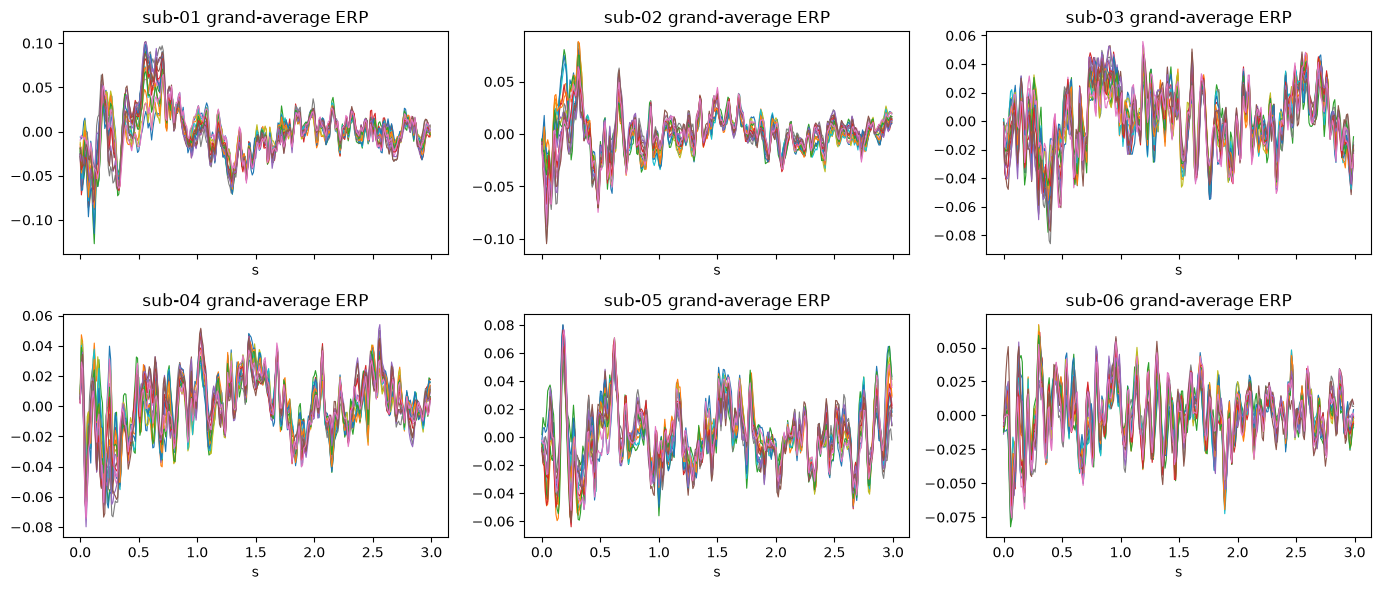

In [4]:
# Quick look: grand-average ERP of every subject (channel traces overlaid). Use it to check which channels
# carry the early ~100 ms / 200-300 ms peaks (auditory-like peaks are usually largest at fronto-central sites).
fig, axs = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
t = np.arange(N_T) / FS
d_plain = get_data(ea=False, remove_mean_erp=False)
for ax, s in zip(axs.ravel(), ALL_SUBJECTS):
    ax.plot(t, d_plain.trn_eeg[s].mean(0).T, lw=0.8); ax.set_title(f'sub-{s:02d} grand-average ERP'); ax.set_xlabel('s')
plt.tight_layout(); plt.show()

## 3. Признаки стимулов: видео и аудио

Каждый набор признаков хранится в `cache/{name}_train.npy` (1000, T, D) и `cache/{name}_test.npy` (102, T, D), где ось T грубая временная ось (по умолчанию 6 бинов по 0,5 с; огибающая звука 30 бинов по 0,1 с). Строка `i` соответствует видео `i+1` (train) и `1001+i` (test).

Блок извлечения ниже запускается один раз; включите нужные флаги в `RUN_EXTRACT`. Нужны GPU, `ffmpeg`, `transformers`. **Экстракторы для V-JEPA 2, VideoMAE, CLAP и Whisper я не мог прогнать без весов и сети; при несовпадении форм токенов поправьте `tokens_to_time`**, остальное проверялось на синтетических данных и коротком тестовом видео.

In [5]:
class FeatureStore:
    '''name -> (train (1000,T,D), test (102,T,D)); backed by ./cache/*.npy.'''
    def __init__(self):
        self.mem = {}

    def add(self, name, train, test):
        self.mem[name] = (np.asarray(train, np.float32), np.asarray(test, np.float32))

    def save(self, name, train, test):
        np.save(CACHE / f'{name}_train.npy', np.asarray(train, np.float32))
        np.save(CACHE / f'{name}_test.npy', np.asarray(test, np.float32))
        self.add(name, train, test)

    def get(self, name):
        if name not in self.mem:
            ptr, pte = CACHE / f'{name}_train.npy', CACHE / f'{name}_test.npy'
            if not (ptr.exists() and pte.exists()):
                raise FileNotFoundError(f'feature set {name!r} is not cached: run the extraction section first')
            self.mem[name] = (np.load(ptr), np.load(pte))
        return self.mem[name]

    def available(self):
        disk = {p.name[:-len('_train.npy')] for p in CACHE.glob('*_train.npy')}
        return sorted(n for n in disk | set(self.mem) if '__' not in n)


STORE = FeatureStore()


def make_synth_store(seed=1, K=16):
    rng = np.random.RandomState(seed)
    Z = SYN['Z']
    for name, noise, D in [('syn_vis', 0.5, 32), ('syn_aud', 1.5, 32)]:
        P, tb = rng.randn(K, D), rng.rand(6, K)
        feats = np.einsum('nk,kd,bk->nbd', Z, P, tb) + noise * rng.randn(len(Z), 6, D)
        STORE.add(name, feats[:N_TRAIN_VIDEOS], feats[N_TRAIN_VIDEOS:])


if USE_SYNTHETIC:
    make_synth_store()
print('cached feature sets:', STORE.available())

cached feature sets: []


In [6]:
import cv2


def video_path(i):
    return (VID_TRN_DIR if i <= N_TRAIN_VIDEOS else VID_TST_DIR) / f'{i:04d}.mp4'


def read_frames(path, n, size=224):
    '''n uniformly spaced RGB frames, centre-cropped to a square and resized: (n, size, size, 3) uint8.'''
    cap, frames = cv2.VideoCapture(str(path)), []
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        frames.append(fr)
    cap.release()
    if not frames:
        raise RuntimeError(f'no frames read from {path}')
    idx = np.linspace(0, len(frames) - 1, n).round().astype(int)
    out = []
    for i in idx:
        fr = frames[i]; h, w = fr.shape[:2]; m = min(h, w)
        fr = fr[(h - m) // 2:(h - m) // 2 + m, (w - m) // 2:(w - m) // 2 + m]
        out.append(cv2.cvtColor(cv2.resize(fr, (size, size), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB))
    return np.stack(out)


def pool_time(x, n):
    '''Average a (T, D) series into n bins (works for T < n by reusing samples).'''
    edges = np.linspace(0, len(x), n + 1)
    out = []
    for b in range(n):
        lo = int(np.floor(edges[b])); hi = max(int(np.ceil(edges[b + 1])), lo + 1)
        out.append(x[min(lo, len(x) - 1):hi].mean(0))
    return np.stack(out)


def tokens_to_time(h, n_t):
    '''(1, N, D) token sequence of a video transformer -> (n_t, D): average the tokens of every time slot.
    Falls back to the global mean if N is not divisible by n_t (check your model's token layout).'''
    h = h[0].float().cpu().numpy()
    if h.shape[0] % n_t != 0:
        return h.mean(0, keepdims=True)
    return h.reshape(n_t, -1, h.shape[-1]).mean(1)


IM_MEAN, IM_STD = np.array([0.485, 0.456, 0.406], np.float32), np.array([0.229, 0.224, 0.225], np.float32)


def load_audio(path, sr=16000, dur=3.0):
    '''Decode the soundtrack with ffmpeg; returns (waveform padded/cropped to dur seconds, has_sound flag).'''
    from scipy.io import wavfile
    n = int(sr * dur)
    tmp = CACHE / 'tmp_audio.wav'
    tmp.unlink(missing_ok=True)
    r = subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', str(path), '-vn', '-ac', '1', '-ar', str(sr), str(tmp)],
                       capture_output=True)
    if r.returncode != 0 or not tmp.exists():
        return np.zeros(n, np.float32), False
    _, w = wavfile.read(tmp)
    w = w.astype(np.float32)
    if np.issubdtype(wavfile.read(tmp)[1].dtype, np.integer):
        w = w / np.iinfo(wavfile.read(tmp)[1].dtype).max
    if w.ndim > 1:
        w = w.mean(1)
    w = np.pad(w, (0, max(0, n - len(w))))[:n]
    return w.astype(np.float32), bool(np.abs(w).max() > 1e-4)

In [10]:
# ---------- extractors: each factory returns fn(path) -> {suffix: (T, D)}; suffix '' -> name = prefix ----------
def extractor_alexnet(n_frames=8):
    from torchvision import models
    net = models.alexnet(weights=models.AlexNet_Weights.DEFAULT).features.to(DEVICE).eval()
    taps = {3: 'l3', 10: 'l10'}                        # features.3 is the layer used by the organisers' baseline
    mean, std = torch.tensor(IM_MEAN, device=DEVICE).view(1, 3, 1, 1), torch.tensor(IM_STD, device=DEVICE).view(1, 3, 1, 1)

    @torch.no_grad()
    def fn(path):
        h = (torch.from_numpy(read_frames(path, n_frames, 224)).to(DEVICE).permute(0, 3, 1, 2).float() / 255 - mean) / std
        out = {}
        for i, layer in enumerate(net):
            h = layer(h)
            if i in taps:
                out[taps[i]] = F.adaptive_avg_pool2d(h, 4).flatten(1).cpu().numpy()   # (n_frames, C*16)
        return out
    return fn


def extractor_dinov2(name='facebook/dinov2-base', n_frames=8):
    from transformers import AutoModel, AutoImageProcessor
    proc, model = AutoImageProcessor.from_pretrained(name), AutoModel.from_pretrained(name).to(DEVICE).eval()
    cat = lambda h: torch.cat([h[:, 0], h[:, 1:].mean(1)], -1).float().cpu().numpy()

    @torch.no_grad()
    def fn(path):
        inp = proc(images=list(read_frames(path, n_frames, 224)), return_tensors='pt').to(DEVICE)
        hs = model(**inp, output_hidden_states=True).hidden_states
        return {'mid': cat(hs[len(hs) // 2]), 'last': cat(hs[-1])}
    return fn


def extractor_clip(name='openai/clip-vit-base-patch32', n_frames=8):
    from transformers import CLIPModel, CLIPProcessor
    proc, model = CLIPProcessor.from_pretrained(name), CLIPModel.from_pretrained(name).to(DEVICE).eval()

    @torch.no_grad()
    def fn(path):
        pix = proc(images=list(read_frames(path, n_frames, 224)), return_tensors='pt')['pixel_values'].to(DEVICE)
        out = model.vision_model(pixel_values=pix, output_hidden_states=True)
        return {'embed': model.visual_projection(out.pooler_output).float().cpu().numpy(),
                'mid': out.hidden_states[len(out.hidden_states) // 2][:, 1:].mean(1).float().cpu().numpy()}
    return fn


def extractor_vjepa2(name='facebook/vjepa2-vitl-fpc64-256', n_frames=64):
    # NOT TESTED without weights: check processor input layout and hidden_states support for your transformers version
    from transformers import AutoModel, AutoVideoProcessor
    proc = AutoVideoProcessor.from_pretrained(name)
    model = AutoModel.from_pretrained(name, torch_dtype=torch.float16 if DEVICE == 'cuda' else torch.float32).to(DEVICE).eval()

    @torch.no_grad()
    def fn(path):
        fr = torch.from_numpy(read_frames(path, n_frames, 256)).permute(0, 3, 1, 2)       # (T, C, H, W)
        inp = proc(fr, return_tensors='pt').to(DEVICE)
        inp = {k: (v.to(model.dtype) if v.is_floating_point() else v) for k, v in inp.items()}
        out = model(**inp, output_hidden_states=True)
        hs = getattr(out, 'hidden_states', None) or (out.last_hidden_state,)
        n_t = n_frames // 2                                                                 # tubelet size 2
        return {'mid': tokens_to_time(hs[len(hs) // 2], n_t), 'last': tokens_to_time(hs[-1], n_t)}
    return fn


def extractor_videomae(name='MCG-NJU/videomae-base', n_frames=16):
    # NOT TESTED without weights. License CC-BY-NC-4.0.
    from transformers import VideoMAEModel, VideoMAEImageProcessor
    proc, model = VideoMAEImageProcessor.from_pretrained(name), VideoMAEModel.from_pretrained(name).to(DEVICE).eval()

    @torch.no_grad()
    def fn(path):
        inp = proc(list(read_frames(path, n_frames, 224)), return_tensors='pt').to(DEVICE)
        hs = model(**inp, output_hidden_states=True).hidden_states
        return {'mid': tokens_to_time(hs[len(hs) // 2], n_frames // 2), 'last': tokens_to_time(hs[-1], n_frames // 2)}
    return fn


def extractor_audio_env(n_mels=32):
    import torchaudio
    mel = torchaudio.transforms.MelSpectrogram(16000, n_fft=400, hop_length=160, n_mels=n_mels)

    def fn(path):
        w, has = load_audio(path)
        m = torch.log(mel(torch.from_numpy(w)) + 1e-6).T.numpy()[:N_T]                    # (300, n_mels) at 100 Hz
        energy = m.mean(1, keepdims=True)
        onset = np.maximum(np.diff(energy, axis=0, prepend=energy[:1]), 0)
        return {'': np.concatenate([m, energy, onset], 1), '__has_audio': np.array([float(has)])}
    return fn


def extractor_whisper(name='openai/whisper-base'):
    # NOT TESTED without weights: Whisper encoder runs at 50 Hz, the first 150 frames are the 3 s clip
    from transformers import WhisperFeatureExtractor, WhisperModel
    fe, enc = WhisperFeatureExtractor.from_pretrained(name), WhisperModel.from_pretrained(name).encoder.to(DEVICE).eval()

    @torch.no_grad()
    def fn(path):
        w, _ = load_audio(path)
        feats = fe(w, sampling_rate=16000, return_tensors='pt').input_features.to(DEVICE)
        hs = enc(feats, output_hidden_states=True).hidden_states
        return {'mid': hs[len(hs) // 2][0, :150].float().cpu().numpy(), 'last': hs[-1][0, :150].float().cpu().numpy()}
    return fn


def extractor_clap(name='laion/clap-htsat-unfused'):
    # NOT TESTED without weights
    from transformers import ClapModel, ClapProcessor
    proc, model = ClapProcessor.from_pretrained(name), ClapModel.from_pretrained(name).to(DEVICE).eval()

    @torch.no_grad()
    def fn(path):
        w, _ = load_audio(path, sr=48000)
        try:
            inp = proc(audios=w, sampling_rate=48000, return_tensors='pt')
        except TypeError:
            inp = proc(audio=w, sampling_rate=48000, return_tensors='pt')
        return {'': model.get_audio_features(**inp.to(DEVICE)).float().cpu().numpy()}
    return fn


EXTRACTORS = {   # prefix -> (factory, number of time bins)
    'alexnet': (extractor_alexnet, 6), 'dinov2': (extractor_dinov2, 6), 'clip': (extractor_clip, 6),
    'vjepa2': (extractor_vjepa2, 6), 'videomae': (extractor_videomae, 6),
    'audio_env': (extractor_audio_env, 30), 'whisper': (extractor_whisper, 6), 'clap': (extractor_clap, 1),
}


def run_extraction(prefix, fn, n_bins=6):
    acc = {}
    for split, ids in [('train', range(1, N_TRAIN_VIDEOS + 1)), ('test', range(TEST_ID0, TEST_ID0 + N_TEST_VIDEOS))]:
        for i in tqdm(ids, desc=f'{prefix} {split}'):
            for k, v in fn(video_path(i)).items():
                v = np.asarray(v, np.float32)
                acc.setdefault(k, {}).setdefault(split, []).append(v if k.startswith('__') else pool_time(v, n_bins))
    for k, d in acc.items():
        STORE.save(f'{prefix}_{k}' if k and not k.startswith('__') else f'{prefix}{k}', np.stack(d['train']), np.stack(d['test']))
    (CACHE / f'.done_{prefix}').touch()


# Set the flags you want and run this cell once (GPU recommended). Already extracted sets are skipped.
RUN_EXTRACT = dict(alexnet=True, dinov2=False, clip=False, vjepa2=False, videomae=False,
                   audio_env=True, whisper=False, clap=False)
if not USE_SYNTHETIC:
    for prefix, on in RUN_EXTRACT.items():
        if on and not (CACHE / f'.done_{prefix}').exists():
            factory, nb_ = EXTRACTORS[prefix]
            run_extraction(prefix, factory(), nb_)
print('cached feature sets:', STORE.available())

audio_env train:   0%|          | 0/1000 [00:00<?, ?it/s]

audio_env test:   0%|          | 0/102 [00:00<?, ?it/s]

cached feature sets: ['alexnet_l10', 'alexnet_l3', 'audio_env']


## 4. Метрики и таргеты

`build_targets` превращает выбранные наборы признаков в одну матрицу таргетов: z-score и PCA **по train-видео**, затем блоки выравниваются по масштабу, чтобы ни одна модальность не доминировала. `mode='global'` усредняет по времени, `mode='temporal'` сохраняет временную ось (нужна для аудио-огибающей).

In [11]:
CHANCE = dict(top1=1 / N_TEST_VIDEOS, top5=5 / N_TEST_VIDEOS, med_rank=(N_TEST_VIDEOS + 1) / 2)


def rank_of_truth(S, true_col):
    return (-S).argsort(1).argsort(1)[np.arange(len(S)), true_col] + 1


def mrr(S, true_col):
    return float((1 / rank_of_truth(S, true_col)).mean())


def retrieval_metrics(S, gt_ids):
    '''S: (n_trials, 102) similarity in the ORIGINAL trial order; gt_ids: true video id per trial (1001..1102).'''
    r = rank_of_truth(S, np.asarray(gt_ids) - TEST_ID0)
    return dict(top1=float((r == 1).mean()), top5=float((r <= 5).mean()), mrr=float((1 / r).mean()), med_rank=float(np.median(r)))


@dataclass
class Targets:
    Tr: np.ndarray    # (1000, P) row i <-> video id i+1
    Te: np.ndarray    # (102, P)  row j <-> video id 1001+j
    names: list


def build_targets(names, mode='global', pca_dim=128, weights=None, store=STORE):
    weights, trs, tes = weights or {}, [], []
    for n in names:
        tr, te = store.get(n)
        if mode == 'global':
            tr, te = tr.mean(1), te.mean(1)
        else:
            tr, te = tr.reshape(len(tr), -1), te.reshape(len(te), -1)
        mu, sd = tr.mean(0), tr.std(0) + 1e-6
        trz, tez = (tr - mu) / sd, (te - mu) / sd
        k = int(min(pca_dim, trz.shape[0] - 1, trz.shape[1]))
        pca = PCA(k, svd_solver='randomized', random_state=SEED).fit(trz)
        trp, tep = pca.transform(trz), pca.transform(tez)
        scale = np.sqrt((trp ** 2).sum(1).mean()) + 1e-8
        trs.append(weights.get(n, 1.0) * trp / scale)
        tes.append(weights.get(n, 1.0) * tep / scale)
    return Targets(np.concatenate(trs, 1).astype(np.float32), np.concatenate(tes, 1).astype(np.float32), list(names))


# ---- helpers shared by the methods ----
def window_idx(win, fs=FS, T=N_T):
    a, b = np.round(np.array(win) * fs).astype(int)
    return slice(int(a), min(int(b), T))


def zrow(x):
    x = x - x.mean(1, keepdims=True)
    return x / (x.std(1, keepdims=True) + 1e-8)


def cos_sim(a, b):
    n = lambda x: x / np.linalg.norm(x, axis=1, keepdims=True).clip(1e-8)
    return n(a) @ n(b).T


def ridge_path(X, Y, alphas):
    '''Closed-form ridge for several alphas via one SVD of X (n x p). X and Y must be centred. Returns [W_alpha].'''
    U, s, Vt = np.linalg.svd(X.astype(np.float64), full_matrices=False)
    UtY = U.T @ Y
    return [(Vt.T @ ((s / (s ** 2 + a))[:, None] * UtY)).astype(np.float32) for a in alphas]


def split_videos(ids, frac=0.15, seed=SEED):
    rng = np.random.RandomState(seed)
    u = np.unique(ids); rng.shuffle(u)
    return set(u[:max(2, int(len(u) * frac))].tolist())


def stack_train(D, subjects=None):
    X, V, S = [], [], []
    for s in (subjects or list(D.trn_eeg)):
        X.append(D.trn_eeg[s]); V.append(D.trn_ids[s]); S.append(np.full(len(D.trn_ids[s]), s))
    return np.concatenate(X), np.concatenate(V), np.concatenate(S)

## 5. Методы

Общий интерфейс: `fit(D, T)` и `score(sub, eeg) -> (n_trials, 102)`. Внутренний hold-out (≈12–15% **train-видео**) используется для подбора α / регуляризации / ранней остановки; тест-записи для этого не нужны.

- **`RidgeEncoding`**: признаки видео → ЭЭГ (как бейзлайн организаторов), совпадение по корреляции измеренной и предсказанной ЭЭГ. `per_subject=True` воспроизводит бейзлайн, `False` обучает одну модель на шести субъектах.
- **`RidgeDecoding`**: ЭЭГ → PCA → эмбеддинг видео, косинус к кандидатам.
- **`RCCA`**: регуляризованный CCA между ЭЭГ-PCA и таргетами.
- **`Contrastive`**: слой на каждого субъекта (17→32) + временная свёртка → эмбеддинг; InfoNCE против MLP над замороженными признаками. Опции: soft-targets, аугментации, ансамбль сидов, `refit`, адаптеры субъектов (`adapt_epochs`).

In [12]:
class RidgeEncoding:
    '''stimulus features -> EEG (forward model); score = correlation of measured vs predicted EEG in a window.'''
    def __init__(self, per_subject=False, win=(0.05, 0.6), alphas=None, trialnorm=True):
        self.per_subject, self.win, self.trialnorm = per_subject, win, trialnorm
        self.alphas = np.logspace(0, 6, 13) if alphas is None else alphas

    def fit(self, D, T):
        self.pred, self.group, self.alpha = {}, {}, {}
        groups = {s: [s] for s in D.trn_eeg} if self.per_subject else {'all': list(D.trn_eeg)}
        sl = window_idx(self.win)
        for g, subs in groups.items():
            for s in subs:
                self.group[s] = g
            E, V, _ = stack_train(D, subs)
            Y, Fe = E.reshape(len(E), -1), T.Tr[V - 1]
            hold = np.isin(V, list(split_videos(V)))
            fm, ym = Fe[~hold].mean(0), Y[~hold].mean(0)
            Ws = ridge_path(Fe[~hold] - fm, Y[~hold] - ym, self.alphas)
            uv = np.unique(V[hold]); true_col = np.searchsorted(uv, V[hold])
            Eh = zrow(E[hold][:, :, sl].reshape(hold.sum(), -1))
            best, best_a = -1, self.alphas[0]
            for a, W in zip(self.alphas, Ws):
                P = ((T.Tr[uv - 1] - fm) @ W + ym).reshape(len(uv), *E.shape[1:])[:, :, sl].reshape(len(uv), -1)
                m = mrr(Eh @ zrow(P).T, true_col)
                if m > best:
                    best, best_a = m, a
            fm, ym = Fe.mean(0), Y.mean(0)
            W = ridge_path(Fe - fm, Y - ym, [best_a])[0]
            self.pred[g] = ((T.Te - fm) @ W + ym).reshape(len(T.Te), *E.shape[1:])
            self.alpha[g] = float(best_a)
        return self

    def score(self, s, eeg, win=None):
        sl = window_idx(win or self.win)
        Pf = self.pred[self.group[s]]
        P = Pf[:, :, sl].reshape(len(Pf), -1)
        M = eeg[:, :, sl].reshape(len(eeg), -1)
        if self.trialnorm:
            M, P = zrow(M), zrow(P)
        return M @ P.T / M.shape[1]


class RidgeDecoding:
    '''EEG -> stimulus embedding (backward model); score = cosine(decoded, candidate embedding).'''
    def __init__(self, win=(0.0, 3.0), eeg_pca=256, alphas=None):
        self.win, self.eeg_pca = win, eeg_pca
        self.alphas = np.logspace(0, 7, 15) if alphas is None else alphas

    def _flat(self, e):
        return e[:, :, window_idx(self.win)].reshape(len(e), -1)

    def fit(self, D, T):
        E, V, _ = stack_train(D)
        X = self._flat(E)
        self.pca = PCA(int(min(self.eeg_pca, X.shape[0] - 1, X.shape[1])), svd_solver='randomized', random_state=SEED).fit(X)
        Z, Y = self.pca.transform(X), T.Tr[V - 1]
        hold = np.isin(V, list(split_videos(V)))
        zm, ym = Z[~hold].mean(0), Y[~hold].mean(0)
        Ws = ridge_path(Z[~hold] - zm, Y[~hold] - ym, self.alphas)
        uv = np.unique(V[hold]); true_col = np.searchsorted(uv, V[hold])
        sc = [mrr(cos_sim((Z[hold] - zm) @ W + ym, T.Tr[uv - 1]), true_col) for W in Ws]
        self.alpha = float(self.alphas[int(np.argmax(sc))])
        self.zm, self.ym, self.T = Z.mean(0), Y.mean(0), T
        self.W = ridge_path(Z - self.zm, Y - self.ym, [self.alpha])[0]
        return self

    def score(self, s, eeg):
        pred = (self.pca.transform(self._flat(eeg)) - self.zm) @ self.W + self.ym
        return cos_sim(pred, self.T.Te)


class RCCA:
    '''Regularised CCA between EEG-PCA and stimulus targets; score = cosine in canonical space.'''
    def __init__(self, win=(0.0, 3.0), eeg_pca=64, k=32, regs=(1e-2, 1e-1, 1.0, 10.0)):
        self.win, self.eeg_pca, self.k, self.regs = win, eeg_pca, k, regs

    @staticmethod
    def _cca(X, Y, reg, k):
        n = len(X)
        Cxx, Cyy, Cxy = X.T @ X / n, Y.T @ Y / n, X.T @ Y / n
        Cxx = Cxx + reg * np.trace(Cxx) / len(Cxx) * np.eye(len(Cxx))
        Cyy = Cyy + reg * np.trace(Cyy) / len(Cyy) * np.eye(len(Cyy))
        Ix, Iy = inv_sqrt(Cxx), inv_sqrt(Cyy)
        U, s, Vt = np.linalg.svd(Ix @ Cxy @ Iy, full_matrices=False)
        k = min(k, len(s))
        return Ix @ U[:, :k], Iy @ Vt.T[:, :k]

    def _flat(self, e):
        return e[:, :, window_idx(self.win)].reshape(len(e), -1)

    def fit(self, D, T):
        E, V, _ = stack_train(D)
        X = self._flat(E)
        self.pca = PCA(int(min(self.eeg_pca, X.shape[0] - 1, X.shape[1])), svd_solver='randomized', random_state=SEED).fit(X)
        Z, Y = self.pca.transform(X), T.Tr[V - 1]
        hold = np.isin(V, list(split_videos(V)))
        uv = np.unique(V[hold]); true_col = np.searchsorted(uv, V[hold])
        xm, ym = Z[~hold].mean(0), Y[~hold].mean(0)
        best, best_reg = -1, self.regs[0]
        for reg in self.regs:
            Wx, Wy = self._cca(Z[~hold] - xm, Y[~hold] - ym, reg, self.k)
            m = mrr(cos_sim((Z[hold] - xm) @ Wx, (T.Tr[uv - 1] - ym) @ Wy), true_col)
            if m > best:
                best, best_reg = m, reg
        self.reg, self.xm, self.ym, self.T = best_reg, Z.mean(0), Y.mean(0), T
        self.Wx, self.Wy = self._cca(Z - self.xm, Y - self.ym, best_reg, self.k)
        return self

    def score(self, s, eeg):
        A = (self.pca.transform(self._flat(eeg)) - self.xm) @ self.Wx
        B = (self.T.Te - self.ym) @ self.Wy
        return cos_sim(A, B)

In [13]:
class SubjectLayer(nn.Module):
    '''Own linear spatial filter per subject (initialised near identity): (B, C, T) -> (B, c_out, T).'''
    def __init__(self, n_subj, c_in, c_out):
        super().__init__()
        self.W = nn.Parameter(torch.eye(c_in, c_out).unsqueeze(0).repeat(n_subj, 1, 1) + 0.01 * torch.randn(n_subj, c_in, c_out))

    def forward(self, x, s):
        return torch.einsum('bct,bcd->bdt', x, self.W[s])


class EEGEncoder(nn.Module):
    def __init__(self, n_subj, c_in=17, c_virt=32, f=64, emb=256, drop=0.3, n_tok=6, k1=25, k2=11):
        super().__init__()
        self.subj = SubjectLayer(n_subj, c_in, c_virt)
        self.net = nn.Sequential(
            nn.Conv1d(c_virt, f, k1, padding=k1 // 2), nn.BatchNorm1d(f), nn.GELU(), nn.AvgPool1d(2), nn.Dropout(drop),
            nn.Conv1d(f, f, k2, padding=k2 // 2), nn.BatchNorm1d(f), nn.GELU(), nn.AvgPool1d(2), nn.Dropout(drop))
        self.pool, self.head = nn.AdaptiveAvgPool1d(n_tok), nn.Linear(f * n_tok, emb)

    def forward(self, x, s):
        h = self.pool(self.net(self.subj(x, s))).flatten(1)
        return F.normalize(self.head(h), dim=-1)


class Net(nn.Module):
    def __init__(self, n_subj, c_in, P, c_virt, f, emb, hid, drop):
        super().__init__()
        self.enc = EEGEncoder(n_subj, c_in, c_virt, f, emb, drop)
        self.stim = nn.Sequential(nn.Linear(P, hid), nn.GELU(), nn.Dropout(drop), nn.Linear(hid, emb))
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))

    def eeg(self, x, s):
        return self.enc(x, s)

    def vid(self, v):
        return F.normalize(self.stim(v), dim=-1)


def clip_loss(e, z, vids, scale, soft_lambda=0.0, tgt=None, soft_tau=0.1):
    '''Symmetric InfoNCE. Trials of the same video (other subjects) inside a batch are masked out as negatives.
    soft_lambda > 0 mixes in soft targets from the similarity of the stimulus targets.'''
    logits = scale.exp().clamp(max=100) * (e @ z.T)
    same = (vids[:, None] == vids[None, :]) & ~torch.eye(len(vids), dtype=torch.bool, device=vids.device)
    logits = logits.masked_fill(same, -1e4)
    y = torch.arange(len(vids), device=vids.device)
    loss = 0.5 * (F.cross_entropy(logits, y) + F.cross_entropy(logits.T, y))
    if soft_lambda > 0:
        t = F.normalize(tgt, dim=-1)
        q = (t @ t.T / soft_tau).masked_fill(same, -1e4).softmax(1)
        loss = (1 - soft_lambda) * loss + soft_lambda * (-(q * F.log_softmax(logits, 1)).sum(1).mean())
    return loss


class Contrastive:
    '''Dual encoder: EEG (subject layer + temporal CNN) vs frozen stimulus features (MLP head), InfoNCE.'''
    def __init__(self, win=(0.0, 3.0), epochs=60, lr=1e-3, wd=1e-2, batch=128, emb=256, hid=512, drop=0.3, c_virt=32, f=64,
                 soft_lambda=0.0, soft_tau=0.1, shift=5, noise=0.1, ch_drop=0.1, n_seeds=1, patience=12,
                 refit=False, adapt_epochs=0, adapt_lr=1e-3, hold_frac=0.12):
        self.__dict__.update({k: v for k, v in locals().items() if k != 'self'})
        if FAST:
            self.epochs, self.patience, self.n_seeds = min(epochs, 3), 2, 1
            self.adapt_epochs = min(adapt_epochs, 1)

    def _augment(self, x):
        if self.shift:
            x = torch.roll(x, int(np.random.randint(-self.shift, self.shift + 1)), dims=-1)   # one random shift per batch
        if self.noise:
            x = x + self.noise * torch.randn_like(x)
        if self.ch_drop:
            x = x * (torch.rand(x.shape[0], x.shape[1], 1, device=x.device) > self.ch_drop).float()
        return x

    @torch.no_grad()
    def _embed_eeg(self, net, E, Sj, bs=512):
        net.eval(); out = []
        for i in range(0, len(E), bs):
            x = torch.tensor(E[i:i + bs], dtype=torch.float32, device=DEVICE)
            s = torch.tensor(np.asarray(Sj[i:i + bs]) - 1, device=DEVICE)
            out.append(net.eeg(x, s).cpu())
        return torch.cat(out).numpy()

    @torch.no_grad()
    def _embed_vid(self, net, Fe):
        net.eval()
        return net.vid(torch.tensor(Fe, dtype=torch.float32, device=DEVICE)).cpu().numpy()

    def _val_mrr(self, net, Ev, Vv, Sv, T):
        uv = np.unique(Vv)
        return mrr(self._embed_eeg(net, Ev, Sv) @ self._embed_vid(net, T.Tr[uv - 1]).T, np.searchsorted(uv, Vv))

    def _train(self, E, V, Sj, T, val=None, fixed_epochs=None):
        Xt, Vt, St = torch.tensor(E, dtype=torch.float32), torch.tensor(V), torch.tensor(Sj - 1)
        Tr = torch.tensor(T.Tr, device=DEVICE)
        net = Net(6, E.shape[1], T.Tr.shape[1], self.c_virt, self.f, self.emb, self.hid, self.drop).to(DEVICE)
        n_ep, bs = (fixed_epochs or self.epochs), min(self.batch, len(Xt))
        opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_ep)
        best, best_ep, best_state, bad = -1, n_ep, None, 0
        for ep in range(n_ep):
            net.train(); perm = torch.randperm(len(Xt))
            for i in range(0, len(Xt) - bs + 1, bs):
                idx = perm[i:i + bs]
                x, v, s = Xt[idx].to(DEVICE), Vt[idx].to(DEVICE), St[idx].to(DEVICE)
                tgt = Tr[v - 1]
                loss = clip_loss(net.eeg(self._augment(x), s), net.vid(tgt), v, net.logit_scale, self.soft_lambda, tgt, self.soft_tau)
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
            sched.step()
            if val is not None:
                m = self._val_mrr(net, *val, T)
                if m > best:
                    best, best_ep, bad = m, ep + 1, 0
                    best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
                else:
                    bad += 1
                    if bad >= self.patience:
                        break
        if best_state is not None:
            net.load_state_dict(best_state)
        return net, best_ep

    def _adapt(self, net, E, V, Sj, T):
        '''Stage 2: fine-tune ONLY the subject-specific spatial filters on each subject's own trials (BN/dropout frozen).'''
        for p in net.parameters():
            p.requires_grad_(False)
        W = net.enc.subj.W; W.requires_grad_(True)
        opt, Tr = torch.optim.Adam([W], lr=self.adapt_lr), torch.tensor(T.Tr, device=DEVICE)
        net.eval()
        for _ in range(self.adapt_epochs):
            for s in np.unique(Sj):
                idx = np.random.permutation(np.where(Sj == s)[0]); bs = min(self.batch, len(idx))
                for i in range(0, len(idx) - bs + 1, bs):
                    b = idx[i:i + bs]
                    x = torch.tensor(E[b], dtype=torch.float32, device=DEVICE)
                    v, ss = torch.tensor(V[b], device=DEVICE), torch.tensor(Sj[b] - 1, device=DEVICE)
                    tgt = Tr[v - 1]
                    loss = clip_loss(net.eeg(x, ss), net.vid(tgt), v, net.logit_scale, self.soft_lambda, tgt, self.soft_tau)
                    opt.zero_grad(); loss.backward(); opt.step()
        for p in net.parameters():
            p.requires_grad_(True)

    def fit(self, D, T):
        self.sl, self.T = window_idx(self.win), T
        E, V, Sj = stack_train(D)
        E = E[:, :, self.sl]
        hold = np.isin(V, list(split_videos(V, self.hold_frac)))
        self.models, self.best_epochs = [], []
        for seed in range(self.n_seeds):
            seed_all(SEED + seed)
            net, ep = self._train(E[~hold], V[~hold], Sj[~hold], T, val=(E[hold], V[hold], Sj[hold]))
            Eu, Vu, Su = E[~hold], V[~hold], Sj[~hold]
            if self.refit:
                net, _ = self._train(E, V, Sj, T, fixed_epochs=ep)
                Eu, Vu, Su = E, V, Sj
            if self.adapt_epochs:
                self._adapt(net, Eu, Vu, Su, T)
            self.models.append(net); self.best_epochs.append(ep)
        return self

    def score(self, s, eeg):
        e, Sj = eeg[:, :, self.sl], np.full(len(eeg), s)
        return sum(self._embed_eeg(m, e, Sj) @ self._embed_vid(m, self.T.Te).T for m in self.models) / len(self.models)

### 5b. Дообучение видео-бэкбона (`finetune_backbone`)

Самая «тяжёлая» ступень лестницы дообучения: последние `n_last` блоков DINOv2 (по умолчанию `dinov2-small`) обучаются **вместе** с ЭЭГ-энкодером на контрастивной цели. Батч состоит из уникальных видео (по одной случайной записи на видео). Кадры берутся из кэша `uint8`. Используйте GPU; в синтетическом режиме подставляется крошечный бэкбон, чтобы проверить код. Это единственный метод, которому не нужны `feats`.

In [14]:
def load_frames(split, n_frames=4, size=224):
    '''uint8 frames (N, n_frames, size, size, 3) for the train or test videos (cached on disk).'''
    if USE_SYNTHETIC:
        Z = SYN['Z']; Z = Z[:N_TRAIN_VIDEOS] if split == 'train' else Z[N_TRAIN_VIDEOS:]
        col = 1 / (1 + np.exp(-Z[:, :3]))
        rng = np.random.RandomState(1)
        return np.clip(col[:, None, None, None, :] * 255 + rng.randn(len(Z), n_frames, 16, 16, 3) * 20, 0, 255).astype(np.uint8)
    p = CACHE / f'frames_{split}_{n_frames}_{size}.npy'
    if not p.exists():
        ids = range(1, N_TRAIN_VIDEOS + 1) if split == 'train' else range(TEST_ID0, TEST_ID0 + N_TEST_VIDEOS)
        np.save(p, np.stack([read_frames(video_path(i), n_frames, size) for i in tqdm(ids, desc=f'frames {split}')]))
    return np.load(p)


class TinyBackbone(nn.Module):
    '''Smoke-test stand-in with the same interface as HFDinoBackbone.'''
    d = 64

    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.GELU(), nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(16, 64))

    def forward(self, x):                       # x: (B, n_frames, 3, H, W) in [0, 1]
        B, nf = x.shape[:2]
        return self.net(x.flatten(0, 1)).view(B, nf, -1).mean(1)


class HFDinoBackbone(nn.Module):
    '''DINOv2 with only the last n_last transformer blocks (+ final norm) trainable; returns the mean CLS over frames.'''
    def __init__(self, name='facebook/dinov2-small', n_last=2):
        super().__init__()
        from transformers import AutoModel
        self.m = AutoModel.from_pretrained(name)
        for p in self.m.parameters():
            p.requires_grad_(False)
        for blk in list(self.m.encoder.layer)[-n_last:]:
            for p in blk.parameters():
                p.requires_grad_(True)
        for p in self.m.layernorm.parameters():
            p.requires_grad_(True)
        self.d = self.m.config.hidden_size
        self.register_buffer('mean', torch.tensor(IM_MEAN).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(IM_STD).view(1, 3, 1, 1))

    def forward(self, x):
        B, nf = x.shape[:2]
        h = self.m(pixel_values=(x.flatten(0, 1) - self.mean) / self.std).last_hidden_state[:, 0]
        return h.view(B, nf, -1).mean(1)


class FinetuneBackbone:
    def __init__(self, backbone='dinov2-small', n_last=2, n_frames=4, size=224, epochs=10, lr_backbone=2e-5, lr_head=1e-3,
                 videos_per_batch=48, emb=256, win=(0.0, 3.0), drop=0.3, hold_frac=0.12, patience=4, noise=0.1):
        self.__dict__.update({k: v for k, v in locals().items() if k != 'self'})
        if FAST:
            self.epochs, self.patience = min(epochs, 2), 2

    @torch.no_grad()
    def _vid_emb(self, frames, idx, bs=32):
        self.bb.eval(); self.head.eval(); out = []
        for i in range(0, len(idx), bs):
            out.append(F.normalize(self.head(self.bb(self._frames(frames, idx[i:i + bs]))), dim=-1).cpu())
        return torch.cat(out).numpy()

    @torch.no_grad()
    def _eeg_emb(self, E, Sj, bs=512):
        self.enc.eval(); out = []
        for i in range(0, len(E), bs):
            x = torch.tensor(E[i:i + bs], dtype=torch.float32, device=DEVICE)
            out.append(self.enc(x, torch.tensor(np.asarray(Sj[i:i + bs]) - 1, device=DEVICE)).cpu())
        return torch.cat(out).numpy()

    def _frames(self, arr, idx):
        return torch.from_numpy(arr[np.asarray(idx)]).to(DEVICE).permute(0, 1, 4, 2, 3).float() / 255

    def fit(self, D, T=None):
        self.sl = window_idx(self.win)
        self.fr_tr, self.fr_te = load_frames('train', self.n_frames, self.size), load_frames('test', self.n_frames, self.size)
        E, V, Sj = stack_train(D); E = E[:, :, self.sl]
        hold = np.isin(V, list(split_videos(V, self.hold_frac)))
        self.bb = (TinyBackbone() if USE_SYNTHETIC else HFDinoBackbone(f'facebook/{self.backbone}', self.n_last)).to(DEVICE)
        self.enc = EEGEncoder(6, E.shape[1], 32, 64, self.emb, self.drop).to(DEVICE)
        self.head = nn.Linear(self.bb.d, self.emb).to(DEVICE)
        self.scale = nn.Parameter(torch.tensor(math.log(1 / 0.07), device=DEVICE))
        opt = torch.optim.AdamW([
            {'params': [p for p in self.bb.parameters() if p.requires_grad], 'lr': self.lr_backbone},
            {'params': list(self.enc.parameters()) + list(self.head.parameters()) + [self.scale], 'lr': self.lr_head}], weight_decay=1e-2)
        by_vid = {}
        for i in np.where(~hold)[0]:
            by_vid.setdefault(int(V[i]), []).append(i)
        vids = np.array(sorted(by_vid)); vpb = min(self.videos_per_batch, len(vids)); steps = max(1, len(vids) // vpb)
        uv = np.unique(V[hold]); true_col = np.searchsorted(uv, V[hold])
        best, bad, best_state = -1, 0, None
        for ep in range(self.epochs):
            self.bb.train(); self.enc.train(); self.head.train()
            for _ in range(steps):
                vb = np.random.choice(vids, vpb, replace=False)
                ti = np.array([np.random.choice(by_vid[int(v)]) for v in vb])
                x = torch.tensor(E[ti], dtype=torch.float32, device=DEVICE)
                x = x + self.noise * torch.randn_like(x)
                e = self.enc(x, torch.tensor(Sj[ti] - 1, device=DEVICE))
                z = F.normalize(self.head(self.bb(self._frames(self.fr_tr, vb - 1))), dim=-1)
                logits = self.scale.exp().clamp(max=100) * (e @ z.T)
                y = torch.arange(len(vb), device=DEVICE)
                loss = 0.5 * (F.cross_entropy(logits, y) + F.cross_entropy(logits.T, y))
                opt.zero_grad(); loss.backward(); opt.step()
            m = mrr(self._eeg_emb(E[hold], Sj[hold]) @ self._vid_emb(self.fr_tr, uv - 1).T, true_col)
            print(f'  ft epoch {ep + 1}: val MRR {m:.4f}')
            if m > best:
                best, bad = m, 0
                best_state = [copy.deepcopy(mod.state_dict()) for mod in (self.bb, self.enc, self.head)]
            else:
                bad += 1
                if bad >= self.patience:
                    break
        for mod, st in zip((self.bb, self.enc, self.head), best_state):
            mod.load_state_dict(st)
        self.vid_te = self._vid_emb(self.fr_te, np.arange(N_TEST_VIDEOS))
        return self

    def score(self, s, eeg):
        return self._eeg_emb(eeg[:, :, self.sl], np.full(len(eeg), s)) @ self.vid_te.T

## 6. Запуск экспериментов и таблица результатов

`run(name, method, feats, ...)` строит таргеты, обучает метод и сохраняет матрицы сходства для **всех шести** субъектов в `RESULTS`. Метрики считаются по sub-01…04. Если хотите сравнивать предобработки, передавайте `prep=dict(...)`.

In [15]:
METHODS = {'ridge_encoding': RidgeEncoding, 'ridge_decoding': RidgeDecoding, 'rcca': RCCA,
           'contrastive': Contrastive, 'finetune_backbone': FinetuneBackbone}
RESULTS = {}


def run(name, method, feats=(), mode='global', pca_dim=128, weights=None, prep=None, **kw):
    t0 = time.time(); seed_all()
    prep = prep or {}
    D = get_data(**prep)
    T = build_targets(list(feats), mode, pca_dim, weights) if feats else None
    M = METHODS[method](**kw)
    M.fit(D, T)
    S = {s: M.score(s, D.tst_eeg[s]) for s in ALL_SUBJECTS}
    RESULTS[name] = dict(S=S, model=M, cfg=dict(method=method, feats=list(feats), mode=mode, pca_dim=pca_dim, prep=prep, kw=kw))
    ms = [retrieval_metrics(S[s], RAW.tst_gt[s]) for s in DEV_SUBJECTS if s in RAW.tst_gt]
    print(f'{name:<34} top1 {np.mean([m["top1"] for m in ms]):.3f}  top5 {np.mean([m["top5"] for m in ms]):.3f}  '
          f'mrr {np.mean([m["mrr"] for m in ms]):.3f}  ({time.time() - t0:.0f}s)')
    return ms


def leaderboard(subjects=DEV_SUBJECTS):
    rows = []
    for name, r in RESULTS.items():
        ms = [retrieval_metrics(r['S'][s], RAW.tst_gt[s]) for s in subjects if s in RAW.tst_gt]
        row = dict(name=name, method=r['cfg']['method'], feats='+'.join(r['cfg']['feats']), mode=r['cfg'].get('mode', ''))
        row.update({k: np.mean([m[k] for m in ms]) for k in ms[0]})
        row.update({f'top1_s{s:02d}': m['top1'] for s, m in zip(subjects, ms)})
        rows.append(row)
    df = pd.DataFrame(rows).sort_values(['top1', 'top5'], ascending=False).reset_index(drop=True)
    return df


def plot_leaderboard(df):
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(df) + 1.5))
    y = np.arange(len(df))
    ax.barh(y + 0.2, df['top1'], 0.4, label='top-1'); ax.barh(y - 0.2, df['top5'], 0.4, label='top-5')
    ax.axvline(CHANCE['top1'], color='C0', ls='--', lw=1); ax.axvline(CHANCE['top5'], color='C1', ls='--', lw=1)
    ax.set_yticks(y); ax.set_yticklabels(df['name']); ax.invert_yaxis(); ax.legend(); ax.set_xlabel('mean over sub-01..04 (dashed = chance)')
    plt.tight_layout(); plt.show()

In [16]:
def have(*names):
    avail = set(STORE.available())
    return all(n in avail for n in names)


if USE_SYNTHETIC:
    VID, AUD, BASE = ['syn_vis'], ['syn_aud'], ['syn_vis']
else:
    VID = [n for n in ['vjepa2_mid', 'dinov2_mid', 'clip_embed'] if have(n)]
    AUD = [n for n in ['audio_env', 'whisper_mid', 'clap'] if have(n)]
    BASE = ['alexnet_l3'] if have('alexnet_l3') else VID[:1]
print('video sets:', VID, '| audio sets:', AUD, '| baseline set:', BASE)

EXPS = []   # (args, kwargs); edit freely


def add(*a, **k):
    EXPS.append((a, k))


NO_ERP = dict(ea=False, remove_mean_erp=False)      # roughly the organisers' preprocessing
ERP_OUT = dict(ea=False, remove_mean_erp=True)
BEST = dict(ea=True, remove_mean_erp=True)

if BASE:
    add('A0 baseline-like (per-subject)', 'ridge_encoding', BASE, prep=NO_ERP, per_subject=True)
    add('A1 + mean-ERP removed', 'ridge_encoding', BASE, prep=ERP_OUT, per_subject=True)
    add('A2 + pooled 6 subjects + EA', 'ridge_encoding', BASE, prep=BEST, per_subject=False)
    add('A3 A2 + full 0-3 s window', 'ridge_encoding', BASE, prep=BEST, per_subject=False, win=(0.0, 3.0))
if VID:
    add('B1 enc video (global)', 'ridge_encoding', VID, prep=BEST, win=(0.0, 3.0))
    add('B2 enc video (temporal)', 'ridge_encoding', VID, mode='temporal', prep=BEST, win=(0.0, 3.0))
    add('B3 dec video', 'ridge_decoding', VID, prep=BEST)
    add('B4 rCCA video', 'rcca', VID, prep=BEST)
if AUD:
    add('C1 enc audio (temporal)', 'ridge_encoding', AUD, mode='temporal', prep=BEST, win=(0.0, 3.0))
    add('C2 dec audio (temporal)', 'ridge_decoding', AUD, mode='temporal', prep=BEST)
if VID and AUD:
    add('D1 enc audio+video', 'ridge_encoding', VID + AUD, mode='temporal', prep=BEST, win=(0.0, 3.0))
    add('D2 dec audio+video', 'ridge_decoding', VID + AUD, mode='temporal', prep=BEST)
    add('D3 rCCA audio+video', 'rcca', VID + AUD, mode='temporal', prep=BEST)
if VID:
    add('E1 contrastive video', 'contrastive', VID, prep=BEST)
if AUD:
    add('E2 contrastive audio', 'contrastive', AUD, mode='temporal', prep=BEST)
if VID and AUD:
    add('E3 contrastive audio+video', 'contrastive', VID + AUD, mode='temporal', prep=BEST)
    add('E4 E3 + soft targets', 'contrastive', VID + AUD, mode='temporal', prep=BEST, soft_lambda=0.3)
    add('E5 E3 + subject adapters', 'contrastive', VID + AUD, mode='temporal', prep=BEST, adapt_epochs=5)
    add('E6 E3 + 3 seeds + refit', 'contrastive', VID + AUD, mode='temporal', prep=BEST, n_seeds=3, refit=True)

for a, k in EXPS:
    try:
        run(*a, **k)
    except Exception as e:
        print(f'!! {a[0]} failed: {type(e).__name__}: {e}')

video sets: [] | audio sets: ['audio_env'] | baseline set: ['alexnet_l3']
A0 baseline-like (per-subject)     top1 0.032  top5 0.120  mrr 0.102  (7s)
A1 + mean-ERP removed              top1 0.027  top5 0.135  mrr 0.100  (19s)
A2 + pooled 6 subjects + EA        top1 0.047  top5 0.164  mrr 0.129  (14s)
A3 A2 + full 0-3 s window          top1 0.049  top5 0.176  mrr 0.132  (4s)
C1 enc audio (temporal)            top1 0.032  top5 0.123  mrr 0.098  (3s)
C2 dec audio (temporal)            top1 0.020  top5 0.123  mrr 0.093  (17s)
E2 contrastive audio               top1 0.022  top5 0.091  mrr 0.082  (487s)


In [17]:
# Optional heavy step: fine-tune the last blocks of DINOv2 together with the EEG encoder (GPU, frames cached on first run).
RUN_FINETUNE = False
if RUN_FINETUNE or USE_SYNTHETIC:
    run('F1 finetune DINOv2 backbone', 'finetune_backbone', prep=BEST, n_last=2, n_frames=4, epochs=10)

,name,method,feats,mode,top1,top5,mrr,med_rank,top1_s01,top1_s02,top1_s03,top1_s04
0,A3 A2 + full 0-3 s window,ridge_encoding,alexnet_l3,global,0.049,0.176,0.132,21.625,0.020,0.078,0.039,0.059
1,A2 + pooled 6 subjects + EA,ridge_encoding,alexnet_l3,global,0.047,0.164,0.129,23.625,0.049,0.039,0.059,0.039
2,C1 enc audio (temporal),ridge_encoding,audio_env,temporal,0.032,0.123,0.098,32.875,0.020,0.039,0.010,0.059
3,A0 baseline-like (per-subject),ridge_encoding,alexnet_l3,global,0.032,0.120,0.102,32.750,0.029,0.020,0.039,0.039
4,A1 + mean-ERP removed,ridge_encoding,alexnet_l3,global,0.027,0.135,0.100,34.625,0.029,0.020,0.020,0.039
5,E2 contrastive audio,contrastive,audio_env,temporal,0.022,0.091,0.082,32.500,0.029,0.020,0.010,0.029
6,C2 dec audio (temporal),ridge_decoding,audio_env,temporal,0.020,0.123,0.093,27.375,0.010,0.020,0.020,0.029


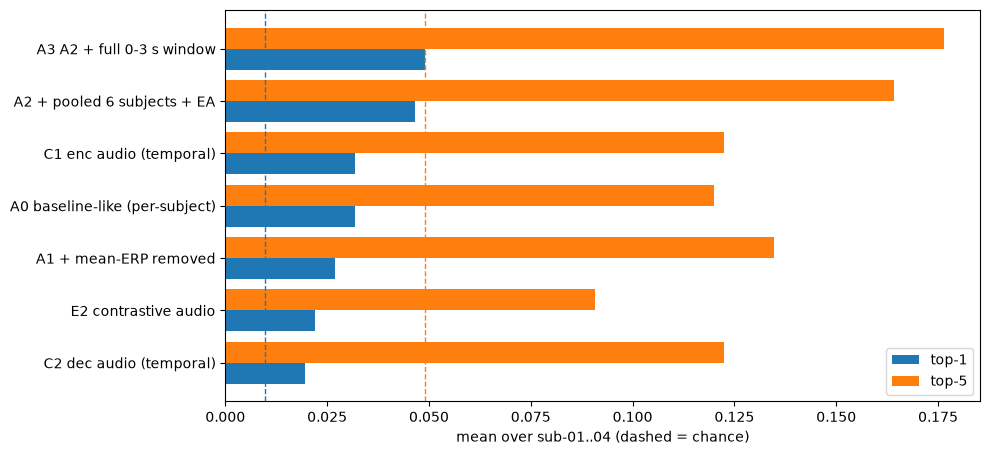

In [18]:
lb = leaderboard()
display(lb.round(3))
plot_leaderboard(lb)

## 7. Слияние и постобработка

- `fuse`: z-score по строке у каждой матрицы сходства, затем взвешенная сумма. Хорошо работает как ансамбль разных таргетов (аудио/видео) и методов.
- `csls`: поправка на «хабы» (кандидаты, похожие на всё подряд); использует только саму матрицу сходства.
- `assignment_boost`: **опционально и спорно**. Каждое из 102 тестовых видео встречается среди 102 записей ровно один раз, и венгерский алгоритм использует это. Организаторы предостерегают от «dataset hacking», поэтому спросите их, допустимо ли это, и в любом случае в отчёте приводите результат с ним и без него.

In [19]:
def znorm(S):
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-8)


def csls(S, k=10):
    rt = np.sort(S, 1)[:, -k:].mean(1, keepdims=True)      # mean sim of each trial to its k nearest candidates
    rc = np.sort(S, 0)[-k:, :].mean(0, keepdims=True)      # mean sim of each candidate to its k nearest trials
    return 2 * S - rt - rc


def assignment_boost(S, bonus=1e3):
    r, c = linear_sum_assignment(-S)
    B = S.copy(); B[r, c] += bonus
    return B


def register_fused(name, names, weights=None, k_csls=0):
    weights = weights or [1.0] * len(names)
    out = {}
    for s in ALL_SUBJECTS:
        S = sum(w * znorm(RESULTS[n]['S'][s]) for n, w in zip(names, weights))
        out[s] = csls(S, k_csls) if k_csls else S
    RESULTS[name] = dict(S=out, model=None, cfg=dict(method='fusion', feats=list(names), mode='', prep={}, kw=dict(weights=weights, k_csls=k_csls)))


def eval_S(S_by_sub, post=None):
    ms = [retrieval_metrics(post(S_by_sub[s]) if post else S_by_sub[s], RAW.tst_gt[s]) for s in DEV_SUBJECTS if s in RAW.tst_gt]
    return {k: round(float(np.mean([m[k] for m in ms])), 4) for k in ms[0]}


top = [n for n in leaderboard()['name'].head(3)]
if len(top) >= 2:
    register_fused('Z1 fusion of top-3', top)
    register_fused('Z2 fusion of top-3 + CSLS', top, k_csls=10)
    print('fusion        :', eval_S(RESULTS['Z1 fusion of top-3']['S']))
    print('fusion + CSLS :', eval_S(RESULTS['Z2 fusion of top-3 + CSLS']['S']))
    print('fusion + assignment (check with organisers first):', eval_S(RESULTS['Z1 fusion of top-3']['S'], post=assignment_boost))

fusion        : {'top1': 0.0686, 'top5': 0.1814, 'mrr': 0.147, 'med_rank': 20.25}
fusion + CSLS : {'top1': 0.0686, 'top5': 0.2255, 'mrr': 0.1532, 'med_rank': 20.5}
fusion + assignment (check with organisers first): {'top1': 0.0613, 'top5': 0.1863, 'mrr': 0.1477, 'med_rank': 20.0}


## 8. Научные анализы

1. **Вклад модальностей:** сравните в таблице строки только-видео, только-аудио и аудио+видео (выше). Если аудио-признаки сами дают retrieval выше шанса, часть «зрительной» точности может быть слуховой.
2. **Когда в ЭЭГ появляется информация о видео:** кривая top-1 по скользящему окну для лучшей `ridge_encoding`-модели.
3. **Влияние окна:** ранний (0–0,6 с) против полного (0–3 с) ответа.
4. **Влияние предобработки:** строки A0, A1, A2.

Для time-resolved RSA слоёв моделей с ЭЭГ используйте Net2Brain (`cvai-roig-lab/Net2Brain`) на кэшированных признаках.

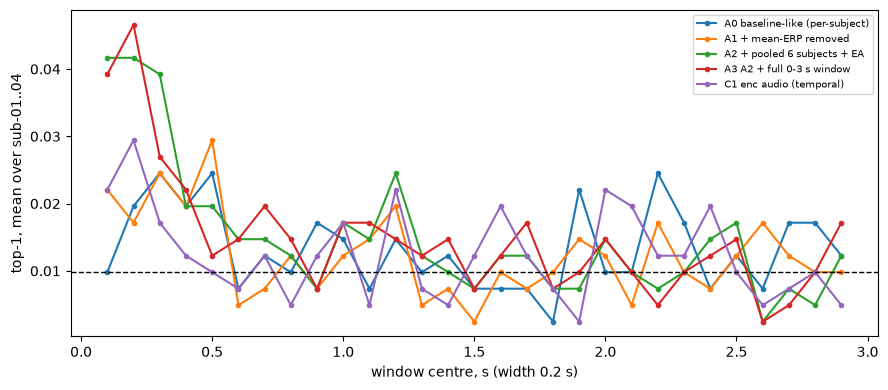

In [20]:
def sliding_window_curve(exp, width=0.2, step=0.1, subjects=DEV_SUBJECTS, label=None):
    r = RESULTS[exp]; M = r['model']
    assert isinstance(M, RidgeEncoding), 'needs a ridge_encoding experiment'
    D = get_data(**r['cfg']['prep'])
    starts = np.arange(0, 3.0 - width + 1e-9, step)
    curve = [np.mean([retrieval_metrics(M.score(s, D.tst_eeg[s], win=(a, a + width)), RAW.tst_gt[s])['top1'] for s in subjects]) for a in starts]
    plt.plot(starts + width / 2, curve, marker='o', ms=3, label=label or exp)
    return starts, curve


enc_exps = [n for n, r in RESULTS.items() if r['cfg']['method'] == 'ridge_encoding']
if enc_exps:
    plt.figure(figsize=(9, 4))
    for n in enc_exps[:5]:
        sliding_window_curve(n)
    plt.axhline(CHANCE['top1'], color='k', ls='--', lw=1)
    plt.xlabel('window centre, s (width 0.2 s)'); plt.ylabel('top-1, mean over sub-01..04'); plt.legend(fontsize=7); plt.tight_layout(); plt.show()

## 9. Сабмишн

`make_submission` пишет `sub-05_ranked_candidate_list.npy` и `sub-06_ranked_candidate_list.npy`, целочисленные массивы 102×102 с **ID видео 1001…1102** (не индексами столбцов) в исходном порядке записей из `tst/sub-XX_tst.npy`. Тот же код сразу применяется к sub-01 и сверяется с `tst_stim`, чтобы проверить формат.

Перед сдачей: пересчитайте выбранный метод с `refit=True` (если он нейросетевой), сохраните веса и конфиги через `save_experiment`, укажите точные имена и версии предобученных моделей в README.

In [21]:
def ranked_from(S, assign=False):
    S = assignment_boost(S) if assign else S
    return (TEST_ID0 + np.argsort(-S, axis=1)).astype(np.int64)      # video IDs, best first, rows in ORIGINAL order


def make_submission(name, assign=False):
    S_by_sub = RESULTS[name]['S']
    for s in HELD_SUBJECTS:
        ranked = ranked_from(S_by_sub[s], assign)
        assert ranked.shape == (N_TEST_VIDEOS, N_TEST_VIDEOS) and all(len(set(r)) == N_TEST_VIDEOS for r in ranked)
        assert ranked.min() == TEST_ID0 and ranked.max() == TEST_ID0 + N_TEST_VIDEOS - 1
        np.save(OUT_DIR / f'sub-{s:02d}_ranked_candidate_list.npy', ranked)
    # format check on a dev subject through the very same code path
    s = DEV_SUBJECTS[0]; r = ranked_from(S_by_sub[s], assign)
    top1 = (r[:, 0] == RAW.tst_gt[s]).mean(); top5 = np.mean([RAW.tst_gt[s][i] in r[i, :5] for i in range(len(r))])
    print(f'saved to {OUT_DIR}; sanity check on sub-{s:02d}: top-1 {top1:.3f} (chance {CHANCE["top1"]:.3f}), top-5 {top5:.3f} (chance {CHANCE["top5"]:.3f})')


def save_experiment(name):
    r = RESULTS[name]; M = r['model']
    if hasattr(M, 'models'):
        torch.save([m.state_dict() for m in M.models], OUT_DIR / f'{name.split()[0]}_weights.pt')
    json.dump(r['cfg'], open(OUT_DIR / f'{name.split()[0]}_config.json', 'w'), indent=2, default=str)


BEST_NAME = leaderboard().loc[0, 'name']
print('best on sub-01..04:', BEST_NAME)
make_submission(BEST_NAME)
save_experiment(BEST_NAME)

best on sub-01..04: Z2 fusion of top-3 + CSLS
saved to submission; sanity check on sub-01: top-1 0.069 (chance 0.010), top-5 0.225 (chance 0.049)
